# 02 · OEE de la línea de producción

**OEE (Overall Equipment Effectiveness / Eficiencia Global de los Equipos)** responde:
*de todo lo que la máquina podía producir en el tiempo planificado, ¿qué porcentaje produjo bien?*

$$\text{OEE} = \text{Disponibilidad} \times \text{Rendimiento} \times \text{Calidad}$$

| Factor | Pregunta | Pérdida que mide |
|---|---|---|
| **Disponibilidad** | ¿Cuánto tiempo estuvo trabajando? | Paros (fallas, cambios de herramienta) |
| **Rendimiento** | ¿Trabajó a la velocidad ideal? | Ir más lento de lo nominal |
| **Calidad** | ¿Cuántas piezas salieron bien? | Piezas defectuosas |

Referencia de la industria: **85 %** se considera OEE de clase mundial.

> Este notebook usa `data/processed/produccion_planta.csv`, generado por `01_exploracion.ipynb`.

## 0. Preparación

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from planta import config
from planta.data.guardado import guardar_csv_procesado
from planta.kpis.oee import calcular_oee, calcular_oee_por_turno, preparar_ciclos_oee

COLOR_PRINCIPAL = "#2a78d6"  # azul
COLOR_ALERTA = "#eb6834"     # naranja: lo que está por debajo de la meta
COLOR_SECUNDARIO = "#b5b4ad" # gris: contexto
META_OEE = 0.85              # referencia de clase mundial (solo para los gráficos)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a3a29b", "axes.grid": True, "grid.color": "#e4e3df",
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "font.size": 10,
})
pd.set_option("display.max_columns", 30)

## 1. Supuestos del cálculo

El dataset **no trae tiempos de paro ni piezas defectuosas**, así que se definen supuestos razonables.
Están en `config.py` para ajustarlos fácilmente con datos reales de una planta.

In [2]:
pd.Series({
    "Duración de cada ciclo (min)": config.MINUTOS_CICLO,
    "Paro por falla de máquina (min)": config.MINUTOS_REPARACION_FALLA,
    "Paro por cambio de herramienta (min)": config.MINUTOS_CAMBIO_HERRAMIENTA,
    "Velocidad nominal (rpm)": config.VELOCIDAD_NOMINAL_RPM,
    "Inicio de la jornada (hora)": config.HORA_INICIO_JORNADA,
}, name="valor").to_frame()

,valor
Duración de cada ciclo (min),30
Paro por falla de máquina (min),20
Paro por cambio de herramienta (min),5
Velocidad nominal (rpm),1500
Inicio de la jornada (hora),6


- Cada ciclo produce **1 pieza**. Si el ciclo tiene falla, la pieza es **defectuosa**.
- El **rendimiento** de un ciclo es `velocidad real / velocidad nominal`, con tope de 100 % (ir más rápido no suma).
- El turno Noche que empieza a las 22:00 y termina a las 06:00 **pertenece a la jornada del día en que empezó** (columna `fecha_turno`).

## 2. Preparar los ciclos

In [3]:
produccion = pd.read_csv(config.RUTA_CSV_PRODUCCION)
ciclos = preparar_ciclos_oee(produccion)
print(f"{len(ciclos)} ciclos | fallas: {ciclos['falla_maquina'].sum()} | "
      f"cambios de herramienta: {ciclos['cambio_herramienta'].sum()}")
ciclos[["id_maquina", "fecha_hora", "fecha_turno", "turno", "falla_maquina",
        "cambio_herramienta", "minutos_paro", "factor_velocidad"]].head()

10000 ciclos | fallas: 339 | cambios de herramienta: 115


,id_maquina,fecha_hora,fecha_turno,turno,falla_maquina,cambio_herramienta,minutos_paro,factor_velocidad
0,M01,2026-09-01T06:00:00,2026-09-01,Mañana,0,0,0,1.000000
1,M01,2026-09-01T06:30:00,2026-09-01,Mañana,0,0,0,0.938667
2,M01,2026-09-01T07:00:00,2026-09-01,Mañana,0,0,0,0.998667
3,M01,2026-09-01T07:30:00,2026-09-01,Mañana,0,0,0,0.955333
4,M01,2026-09-01T08:00:00,2026-09-01,Mañana,0,0,0,0.938667


## 3. Un turno calculado paso a paso
Para entender la fórmula, veamos un turno con una falla: **M01, jornada 2026-09-02, turno Mañana**.

In [4]:
oee_turnos = calcular_oee_por_turno(produccion)
ejemplo = oee_turnos[
    (oee_turnos["id_maquina"] == "M01")
    & (oee_turnos["fecha_turno"] == "2026-09-02")
    & (oee_turnos["turno"] == "Mañana")
].iloc[0]

print(f"Tiempo planificado : {ejemplo['ciclos']} ciclos x {config.MINUTOS_CICLO} min = {ejemplo['tiempo_planificado_min']} min")
print(f"Paros              : {ejemplo['fallas']} falla(s) x {config.MINUTOS_REPARACION_FALLA} + "
      f"{ejemplo['cambios_herramienta']} cambio(s) x {config.MINUTOS_CAMBIO_HERRAMIENTA} = {ejemplo['tiempo_paro_min']} min")
print(f"Disponibilidad     : {ejemplo['tiempo_operativo_min']} / {ejemplo['tiempo_planificado_min']} = {ejemplo['disponibilidad']:.2%}")
print(f"Rendimiento        : promedio de velocidad real/nominal = {ejemplo['rendimiento']:.2%}")
print(f"Calidad            : {ejemplo['piezas_buenas']} buenas / {ejemplo['ciclos']} = {ejemplo['calidad']:.2%}")
print(f"OEE                : {ejemplo['disponibilidad']:.4f} x {ejemplo['rendimiento']:.4f} x {ejemplo['calidad']:.4f} = {ejemplo['oee']:.2%}")

Tiempo planificado : 16 ciclos x 30 min = 480 min
Paros              : 1 falla(s) x 20 + 0 cambio(s) x 5 = 20 min
Disponibilidad     : 460 / 480 = 95.83%
Rendimiento        : promedio de velocidad real/nominal = 97.77%
Calidad            : 15 buenas / 16 = 93.75%
OEE                : 0.9583 x 0.9777 x 0.9375 = 87.84%


## 4. OEE de toda la planta

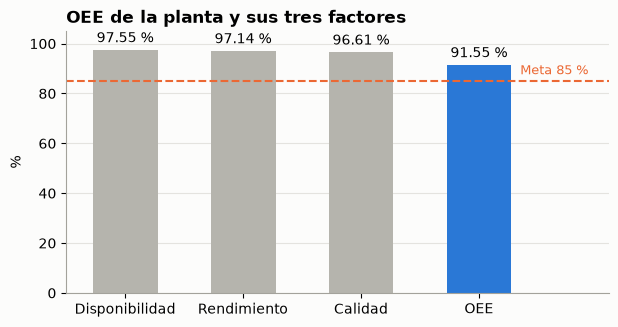

In [5]:
oee_planta = calcular_oee(ciclos.assign(planta="Planta"), ["planta"]).iloc[0]
factores = oee_planta[["disponibilidad", "rendimiento", "calidad", "oee"]].astype(float)
factores.index = ["Disponibilidad", "Rendimiento", "Calidad", "OEE"]

figura, eje = plt.subplots(figsize=(7, 3.4))
colores = [COLOR_SECUNDARIO] * 3 + [COLOR_PRINCIPAL]
barras = eje.bar(factores.index, factores.values * 100, color=colores, width=0.55)
eje.bar_label(barras, fmt="%.2f %%", padding=3)
eje.axhline(META_OEE * 100, color=COLOR_ALERTA, linewidth=1.5, linestyle="--")
eje.text(3.35, META_OEE * 100 + 1.5, "Meta 85 %", color=COLOR_ALERTA, ha="left", va="bottom", fontsize=9)
eje.set_xlim(-0.5, 4.1)
eje.set_ylim(0, 105)
eje.set_ylabel("%")
eje.set_title("OEE de la planta y sus tres factores")
eje.grid(axis="x", visible=False)
plt.show()

**Conclusión:** el OEE de la planta es **91.55 %**, por encima de la meta de 85 %.

- Los tres factores están cerca entre sí: disponibilidad 97.55 %, rendimiento 97.14 % y calidad 96.61 %.
- Como el OEE **multiplica** los factores, tres pérdidas pequeñas (~3 % cada una) se acumulan en una pérdida de ~8.5 %.

> **Para ser transparentes:** 91.55 % es alto para una planta real (lo común es 60–85 %). Sale alto porque la simulación **solo incluye dos tipos de paro** (fallas y cambios de herramienta). Una planta real también pierde tiempo en preparación entre lotes, micro-paros, descansos y falta de material.

## 5. OEE por máquina

In [6]:
oee_maquinas = calcular_oee(ciclos, ["id_maquina"])
oee_maquinas[["id_maquina", "ciclos", "fallas", "cambios_herramienta", "tiempo_paro_min",
              "disponibilidad", "rendimiento", "calidad", "oee"]]

,id_maquina,ciclos,fallas,cambios_herramienta,tiempo_paro_min,disponibilidad,rendimiento,calidad,oee
0,M01,1997,52,23,1155,0.9807,0.9717,0.9740,0.9282
1,M02,2038,53,23,1175,0.9808,0.9713,0.9740,0.9279
2,M03,1965,150,22,3110,0.9472,0.9710,0.9237,0.8495
3,M04,2029,46,23,1035,0.9830,0.9711,0.9773,0.9329
4,M05,1971,38,24,880,0.9851,0.9721,0.9807,0.9392


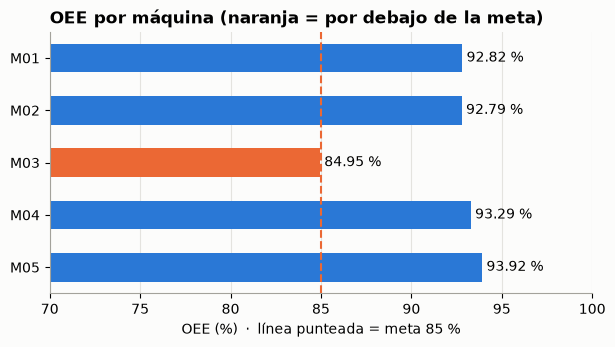

In [7]:
figura, eje = plt.subplots(figsize=(7, 3.4))
colores = [COLOR_ALERTA if valor < META_OEE else COLOR_PRINCIPAL for valor in oee_maquinas["oee"]]
barras = eje.barh(oee_maquinas["id_maquina"], oee_maquinas["oee"] * 100, color=colores, height=0.55)
eje.bar_label(barras, fmt="%.2f %%", padding=3)
eje.axvline(META_OEE * 100, color=COLOR_ALERTA, linewidth=1.5, linestyle="--")
eje.set_xlim(70, 100)
eje.invert_yaxis()
eje.set_xlabel("OEE (%)  ·  línea punteada = meta 85 %")
eje.set_title("OEE por máquina (naranja = por debajo de la meta)")
eje.grid(axis="y", visible=False)
plt.show()

**Conclusión:** **M03 es la única máquina por debajo de la meta (84.95 %)**.

- Tiene **150 fallas**, unas 3 veces más que las otras, y por eso **3 110 min de paro**, casi el triple que las demás.
- Pierde en **disponibilidad** (94.72 %) y en **calidad** (92.37 %), porque cada falla causa paro **y** una pieza defectuosa.
- Su **rendimiento** (97.10 %) es igual al de las demás: no trabaja más lento, **se detiene más**.
- Las otras cuatro máquinas están entre **92.79 % y 93.92 %**.

## 6. OEE por turno

In [8]:
calcular_oee(ciclos, ["turno"]).set_index("turno").loc[
    ["Mañana", "Tarde", "Noche"], ["ciclos", "fallas", "disponibilidad", "rendimiento", "calidad", "oee"]
]

,ciclos,fallas,disponibilidad,rendimiento,calidad,oee
turno,,,,,,
Mañana,3360,117,0.9749,0.9716,0.9652,0.9143
Tarde,3331,113,0.9754,0.9706,0.9661,0.9147
Noche,3309,109,0.9761,0.9721,0.9671,0.9176


**Conclusión:** **no hay diferencia entre turnos** (91.43 % a 91.76 %). Las fallas se reparten casi igual: 117 en Mañana, 113 en Tarde y 109 en Noche.

Es lo esperado, porque la simulación no hace que un turno trabaje peor que otro. En una planta real esta tabla sirve para detectar, por ejemplo, si el turno Noche tiene menos personal de mantenimiento o más paros.

## 7. Evolución diaria del OEE
OEE por máquina y jornada. Se resalta **M03** y las demás quedan en gris como contexto.

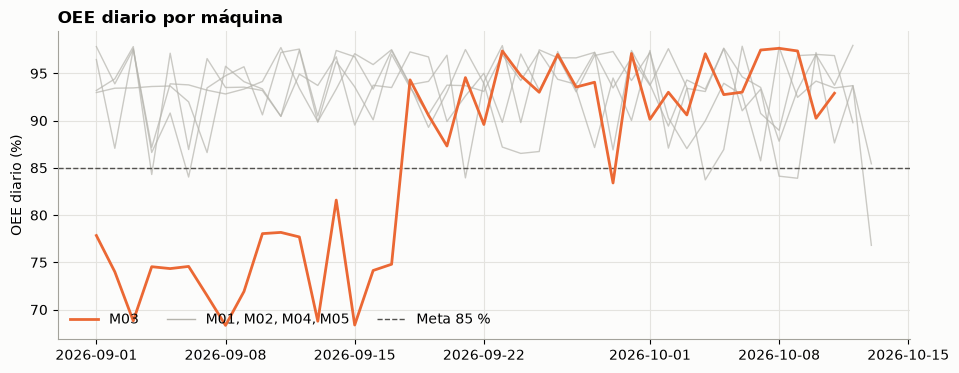

In [9]:
oee_diario = calcular_oee(ciclos, ["id_maquina", "fecha_turno"])

figura, eje = plt.subplots(figsize=(11, 4))
for maquina, grupo in oee_diario.groupby("id_maquina"):
    es_m03 = maquina == "M03"
    eje.plot(grupo["fecha_turno"], grupo["oee"] * 100,
             color=COLOR_ALERTA if es_m03 else COLOR_SECUNDARIO,
             linewidth=2 if es_m03 else 1, alpha=1 if es_m03 else 0.7,
             label="M03" if es_m03 else None, zorder=3 if es_m03 else 2)
eje.plot([], [], color=COLOR_SECUNDARIO, linewidth=1, label="M01, M02, M04, M05")
eje.axhline(META_OEE * 100, color="#52514e", linewidth=1, linestyle="--", label="Meta 85 %")
eje.set_ylabel("OEE diario (%)")
eje.set_title("OEE diario por máquina")
eje.legend(loc="lower left", frameon=False, ncol=3)
plt.show()

In [10]:
dias_bajo_meta = (oee_diario.assign(bajo_meta=oee_diario["oee"] < META_OEE)
                  .groupby("id_maquina")["bajo_meta"].agg(dias="size", dias_bajo_meta="sum"))
dias_bajo_meta

,dias,dias_bajo_meta
id_maquina,,
M01,42,1
M02,43,3
M03,41,18
M04,43,1
M05,42,2


El gráfico muestra que M03 cambia a mediados de septiembre. Comparemos los dos periodos:

In [11]:
ciclos_m03 = ciclos[ciclos["id_maquina"] == "M03"].assign(
    periodo=lambda d: (d["fecha_turno"] >= "2026-09-18").map({False: "1-17 sep", True: "desde 18 sep"}),
    diferencia_temperatura_c=lambda d: d["temperatura_proceso_c"] - d["temperatura_aire_c"],
)
comparacion = calcular_oee(ciclos_m03, ["periodo"]).set_index("periodo")[["ciclos", "fallas", "oee"]]
comparacion["fallas_calor"] = ciclos_m03.groupby("periodo")["falla_disipacion_calor"].sum()
comparacion["temp_aire_prom_c"] = ciclos_m03.groupby("periodo")["temperatura_aire_c"].mean().round(2)
comparacion["dif_temp_prom_c"] = ciclos_m03.groupby("periodo")["diferencia_temperatura_c"].mean().round(2)
comparacion

,ciclos,fallas,oee,fallas_calor,temp_aire_prom_c,dif_temp_prom_c
periodo,,,,,,
1-17 sep,816,123,0.7391,107,29.42,8.26
desde 18 sep,1149,27,0.9325,1,29.66,9.37


**Conclusión:** el problema de M03 **no es constante, tiene fecha**.

- **Del 1 al 17 de septiembre**, M03 estuvo casi todos los días por debajo de la meta: su OEE fue **73.91 %**, con 123 fallas, **107 de ellas por calor**.
- **Desde el 18 de septiembre** se comporta como las demás: OEE de **93.25 %**, 27 fallas y solo **1** por calor.
- La temperatura del aire fue parecida en los dos periodos (~29.5 °C). Lo que cambió fue la **diferencia entre la temperatura del proceso y la del aire**: **8.26 °C** en el primer periodo y **9.37 °C** en el segundo. Con menos de ~8.6 °C de diferencia, el calor no se disipa y la máquina falla.

En total, M03 tuvo **18 días bajo la meta**; las demás máquinas, entre 1 y 3.

> **Lectura para la planta:** en esas dos semanas, M03 operó con muy poco margen térmico. La recomendación sería revisar su refrigeración y **vigilar la diferencia de temperatura**, que es justo lo que el modelo de IA del notebook 03 y las alertas de n8n pueden hacer en tiempo real.

## 8. Turnos por debajo de la meta
Esta es la tabla que se guardará para Power BI: **una fila por máquina, jornada y turno**.

In [12]:
print(f"Turnos totales: {len(oee_turnos)}")
print(f"Turnos con OEE < 85 %: {(oee_turnos['oee'] < META_OEE).sum()}")
print(f"Turnos incompletos (menos de 16 ciclos): {(oee_turnos['ciclos'] < 16).sum()}")
(oee_turnos[oee_turnos["oee"] < META_OEE]["id_maquina"].value_counts()
 .rename("turnos_bajo_meta").to_frame())

Turnos totales: 627
Turnos con OEE < 85 %: 80
Turnos incompletos (menos de 16 ciclos): 5


,turnos_bajo_meta
id_maquina,
M03,42
M01,12
M02,11
M05,8
M04,7


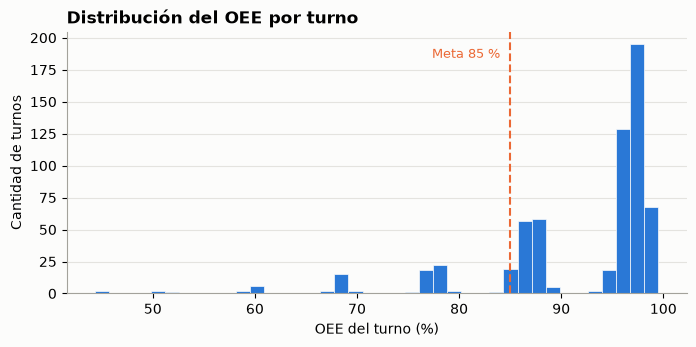

In [13]:
figura, eje = plt.subplots(figsize=(8, 3.4))
eje.hist(oee_turnos["oee"] * 100, bins=40, color=COLOR_PRINCIPAL, edgecolor="#fcfcfb", linewidth=0.5)
eje.axvline(META_OEE * 100, color=COLOR_ALERTA, linewidth=1.5, linestyle="--")
eje.text(META_OEE * 100 - 1, eje.get_ylim()[1] * 0.9, "Meta 85 %", color=COLOR_ALERTA, ha="right", fontsize=9)
eje.set_xlabel("OEE del turno (%)")
eje.set_ylabel("Cantidad de turnos")
eje.set_title("Distribución del OEE por turno")
eje.grid(axis="x", visible=False)
plt.show()

In [14]:
oee_turnos.nsmallest(10, "oee")[["id_maquina", "fecha_turno", "turno", "ciclos", "fallas",
                                   "tiempo_paro_min", "disponibilidad", "calidad", "oee"]]

,id_maquina,fecha_turno,turno,ciclos,fallas,tiempo_paro_min,disponibilidad,calidad,oee
267,M03,2026-09-05,Tarde,16,6,120,0.7500,0.6250,0.4432
298,M03,2026-09-16,Mañana,16,6,120,0.7500,0.6250,0.4477
257,M03,2026-09-02,Noche,16,5,105,0.7812,0.6875,0.5037
252,M02,2026-10-13,Tarde,6,2,40,0.7778,0.6667,0.5087
297,M03,2026-09-15,Tarde,16,5,105,0.7812,0.6875,0.5156
565,M05,2026-09-21,Tarde,16,4,85,0.8229,0.7500,0.5912
254,M03,2026-09-01,Noche,16,4,80,0.8333,0.7500,0.5930
262,M03,2026-09-04,Mañana,16,4,80,0.8333,0.7500,0.5974
275,M03,2026-09-08,Noche,16,4,80,0.8333,0.7500,0.5988
268,M03,2026-09-06,Mañana,16,4,80,0.8333,0.7500,0.5996


**Conclusión:**

- **80 de 627 turnos** (12.8 %) quedaron por debajo de 85 %, y **42 de ellos son de M03**.
- Los peores turnos son de M03, con **5 o 6 fallas en 16 ciclos** y OEE entre **44 % y 52 %**.
- En el cuarto lugar aparece un turno de M02 con **solo 6 ciclos**: es el último turno de la simulación, que quedó a medias. En los turnos cortos, **una sola falla pesa mucho más**. En Power BI conviene mostrar la columna `ciclos` junto al OEE para no sacar conclusiones de turnos incompletos.

## 9. Guardar `oee_turnos.csv`
Contrato de datos: UTF-8, separador coma, fechas ISO 8601. Los indicadores van como **decimales entre 0 y 1**
(en Power BI se les da formato de porcentaje).

In [15]:
ruta = guardar_csv_procesado(oee_turnos, config.RUTA_CSV_OEE)
print("Guardado en:", ruta.relative_to(config.RAIZ_PROYECTO))
print(f"{len(oee_turnos)} filas x {oee_turnos.shape[1]} columnas")
print(list(oee_turnos.columns))

Guardado en: data\processed\oee_turnos.csv
627 filas x 15 columnas
['id_maquina', 'fecha_turno', 'turno', 'ciclos', 'tiempo_planificado_min', 'tiempo_paro_min', 'tiempo_operativo_min', 'fallas', 'cambios_herramienta', 'piezas_buenas', 'piezas_defectuosas', 'disponibilidad', 'rendimiento', 'calidad', 'oee']


## 10. Conclusiones generales

1. **OEE de la planta: 91.55 %**, por encima de la meta de clase mundial (85 %), con la salvedad de que la simulación solo incluye fallas y cambios de herramienta como paros.
2. **M03 es la única máquina bajo la meta (84.95 %)**. Su problema se concentra del **1 al 17 de septiembre**, cuando la diferencia de temperatura fue muy baja y tuvo 107 fallas por calor. Después se normaliza.
3. **Las pérdidas vienen de las fallas, no de la velocidad**: el rendimiento es casi igual en todas las máquinas (~97 %); lo que separa a M03 es la disponibilidad y la calidad.
4. **Los turnos no se diferencian**, porque la simulación no los distingue.
5. **`oee_turnos.csv`** tiene 627 filas (máquina × jornada × turno) para el dashboard de Power BI.

**Siguiente paso:** el notebook `03_modelo_fallas.ipynb` entrena el modelo que **anticipa** estas fallas antes de que bajen el OEE.